# Housing Index Mexico

Notebook to create the New Housing Price Index for Mexico as a whole and for its main metropolitan areas

@roman

8/10/2025

In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import ticker
import matplotlib.colors as mcolors
import seaborn as sns
import yaml
import warnings
from shapely.geometry import Polygon
from tqdm import tqdm

import statsmodels.formula.api as smf
import statsmodels.api as sm
import h3

import mlflow
import xgboost as xgb
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.model_selection import train_test_split

In [2]:
# Settings
pd.set_option('display.max_columns', 500)

# suppress seaborn warnings
warnings.filterwarnings("ignore", module="seaborn")
warnings.filterwarnings("ignore", module="pandas")

---
# Settings

In [3]:
# Settings
# dir
DIR_DATA = '../../data'
DIR_RESULTS = '../../results'
DIR_MODELS = '../../models'
FILE_PROPERTIES = f"{DIR_DATA}/processed/properties_predicted_a81c87e6bb1a40fdbc4803b8ed3eb807.parquet"

---
# Data & Model

## Data

In [4]:
# read parquet, index is observation_id
df_properties = pd.read_parquet(FILE_PROPERTIES)

# set index
df_properties = df_properties.set_index('observation_id')

# look
print(df_properties.shape)
df_properties.head()

(1908483, 132)


,y,y_pred,y_fitted,y_pred_fitted,set,half_bathrooms,full_bathrooms,property_class_more_common_in_area,neighborhood,constructor,zip_code,age_in_months,parking_lots,valuation_date,potable_water_service_id,lighting_service_id,sidewalk_id,project_quality_id,property_class_id,conservation_status_id,controller_id,elevator_service_id,state_id,equipment_id,curb_id,infrastructure_service_id,road_materials_id,municipality_id,grantor_id,urban_proximity_id,water_collection_service_id,electrical_supply_service_id,telephone_service_supply_id,property_type_id,public_transportation_service_id,valuation_unit_id,valuation_professional_id,level,total_levels,purpose_of_appraisal,bedrooms,built_area,saleable_area,land_area,rentable_units,rentable_units_subject_property,current_use,market_price,price,built_price,land_price,access_routes,remaining_useful_life,property_id,city_cluster,ppsm_comps,ppsm_lower_comps,ppsm_upper_comps,num_neighbors,distance_to_ocean,ocean_label,accessory_area,hex_id,count_supermarkets_at_1km,count_hospitals_at_5km,count_metro_at_1km,count_schools_at_1km,count_restaurants_at_1km,tam_loc,est_socio,clase_hog,sexo_jefe,edad_jefe,educa_jefe,tot_integ,mayores,menores,p12_64,p65mas,percep_ing,ing_cor,estim_alqu,otros_ing,gasto_mon,vivienda,alquiler,pred_cons,cuidados,tipo_viv,antiguedad,cuart_dorm,tenencia,renta,estim_pago,pago_viv,pago_mesp,tipo_adqui,viv_usada,tipo_finan,escrituras,tot_resid,tot_hom,tot_muj,tot_hog,total_viviendas,lag_year_inpc,lag_3months_em_avg_pct_change_inpc,lag_year_general_minimum_wage,lag_3months_em_avg_general_wage,ppsm_terrain,ppsm_terrain_lower,ppsm_terrain_upper,hex_longitude,hex_latitude,hex_embedding_1_d16_v2,hex_embedding_2_d16_v2,hex_embedding_3_d16_v2,hex_embedding_4_d16_v2,hex_embedding_5_d16_v2,hex_embedding_6_d16_v2,hex_embedding_7_d16_v2,hex_embedding_8_d16_v2,hex_embedding_9_d16_v2,hex_embedding_10_d16_v2,hex_embedding_11_d16_v2,hex_embedding_12_d16_v2,hex_embedding_13_d16_v2,hex_embedding_14_d16_v2,hex_embedding_15_d16_v2,hex_embedding_16_d16_v2,longitude,latitude
observation_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
ac771cca-59a9-4c2d-81ac-f6091587bac3,9950.819672,9433.436523,-0.629089,-0.749726,train,0,1,3,LOMAS DE ZAPOPAN,NO APLICA,45130,56,1,2019-11-21,1,2,1,1,3,4,7b7e7c13-1454-47e7-a27e-5b569619598e,2,14,4,1,3,3,120,98013144-6a9f-4e08-9255-cb54568d2f5a,3,1,1,1,4,1,5735943b-99a4-4f76-a3d3-96194f0965c1,11ba1f99-422c-4e81-aa9c-a2407c039b8f,6,1,S/D,2,61,61,61,16,1,DEPARTAMENTO EN CONDOMINIO,607216,607000,255327,254204,PERIFERICO NORTE MANUEL GOMEZ MORIIN VIALIDAD ...,34,1a4af054-4dd6-5b71-8d5d-9a84cbbf85e4,11,9968,8427,12076,60,100000,no_ocean,0.000000,8949ab4b233ffff,1,5,0,0,0,1.144531,3.107422,2,1,48.46875,7.417969,3.406250,2.718750,0.686523,2.482422,0.235840,2.291016,90376.351562,12069.535156,51.071159,59082.535156,5765.106445,3271.613037,561.659363,2965.760254,1.0,14.921875,2.251953,4,1119.196899,4116.594238,1026.997437,0.372594,1.0,0.184082,5,1,3.472656,1.706055,1.766602,1.020508,362657,102.3125,0.001171,100.6875,0.113525,7207,4242,11219,20.747093,-103.399807,0.633783,0.043142,0.655791,0.796496,2.572114,-0.858608,0.533800,0.563197,-0.593725,-2.054551,-4.169343,0.763111,-1.482679,0.038740,0.792813,-1.056954,-103.399017,20.747696
11119915-2970-484b-81d2-ebeb6e35d933,7257.142857,7560.211914,-1.342295,-1.249858,train,0,1,3,BENITO JUAREZ,NO APLICA,88276,204,1,2019-11-26,0,0,0,0,3,4,d6d626a9-6dbe-4f1a-bf72-5a0c493bd291,2,28,4,0,3,3,027,98013144-6a9f-4e08-9255-cb54568d2f5a,2,0,0,0,2,0,caa0e4b2-ccc9-4b2a-8c42-6c5e89bb6511,685eb233-ffab-414d-a88a-4bc42419b9eb,3,1,S/D,2,53,70,102,1,0,<NA>,508245,508000,273551,133314,<NA>,43,8a051508-8d67-5f0b-b93a-f82c6665318c,58,8129,6720,10147,60,100000,no_ocean,17.139999,894880da35bffff,0,1,0,0,0,1.000000,2.548828,2,1,50.84375,5.835938,3.410156,2.630859,0.777832,2.289062,0.343506,2.269531,53817.222656,4961.445312,83.217941,34907.683594,4245.199219,1265.920532,89.871

In [5]:
# new features
first_date_obs = df_properties['valuation_date'].min()
df_properties = (
    df_properties
    .assign(
        # quarters since appraisal
        quarters_since_first_appraisal=lambda x: (
            x['valuation_date'] - first_date_obs
            ).dt.days / (30.4 * 3),
        # recategorizations
        is_new=lambda x:
            np.where(x['age_in_months'].le(1), 'new', 'used'),
        conservacion_recat=lambda x:
            x['conservation_status_id'].replace({7: 3.5}).astype(int),
        is_renovated=lambda x:
            np.where(x['conservation_status_id'].ge(7), 'renovated', 'not_renovated'),
    )
    .assign(
        is_new=lambda x: x['is_new'].astype('category'),
    )
)



## Cities

In [6]:
# read cities shapes in parquet
gdf_cities = gpd.read_parquet(f"{DIR_DATA}/misc/cities.parquet")

# look
print(gdf_cities.shape)
gdf_cities.head()


(114, 3)


,geometry,cluster,total_properties
0,"POLYGON ((3766192.137 1038920.719, 3766072.241...",0,49294
1,"POLYGON ((2106201.674 1838908.292, 2106105.496...",1,41078
2,"POLYGON ((2083964.935 2167068.796, 2083854.591...",2,49914
3,"POLYGON ((3695976.760 913468.113, 3695883.500 ...",3,4945
4,"POLYGON ((2691489.214 1478562.321, 2691414.834...",4,224732


## Embeddings

In [7]:
# read parquet
gdf_hex_embeddings = pd.read_parquet("../../data/misc/hex_embeddings_d16_v2.parquet")

# columns with hex_embeddings add sufix d16
gdf_hex_embeddings = gdf_hex_embeddings.rename(
    columns=lambda x: x + "_d16_v2" if x not in ["hex_id"] else x
)

# look
print(gdf_hex_embeddings.shape)
gdf_hex_embeddings.head()

(261712, 17)


,hex_id,hex_embedding_1_d16_v2,hex_embedding_2_d16_v2,hex_embedding_3_d16_v2,hex_embedding_4_d16_v2,hex_embedding_5_d16_v2,hex_embedding_6_d16_v2,hex_embedding_7_d16_v2,hex_embedding_8_d16_v2,hex_embedding_9_d16_v2,hex_embedding_10_d16_v2,hex_embedding_11_d16_v2,hex_embedding_12_d16_v2,hex_embedding_13_d16_v2,hex_embedding_14_d16_v2,hex_embedding_15_d16_v2,hex_embedding_16_d16_v2
0,89450984803ffff,1.226548,-2.105018,0.980468,0.004962,1.388463,-3.114058,0.175245,-0.141921,-1.121091,-1.674633,0.176828,0.982042,-2.988769,-0.198455,-2.142136,-1.020302
1,89450984807ffff,1.244653,-2.061231,0.867655,-0.035147,1.327668,-3.105197,0.259648,-0.149245,-1.162221,-1.612379,0.207615,0.977444,-3.007813,-0.191676,-2.067218,-1.100550
2,8945098480bffff,1.298778,-2.005947,1.099923,-0.111693,1.201540,-3.093980,0.316485,-0.050870,-1.329637,-1.730504,0.155120,1.143537,-3.026915,-0.121923,-2.051444,-1.063948
3,8945098480fffff,1.197906,-1.991767,0.976100,-0.100657,1.437752,-3.219944,0.211685,-0.054004,-1.168892,-1.820608,0.153301,0.834648,-2.919081,-0.141560,-1.947374,-1.189573
4,89450984813ffff,1.243597,-1.919230,1.025213,0.056413,1.146621,-3.069181,0.277293,-0.204666,-1.146666,-1.496874,0.192501,1.269446,-3.082055,-0.237326,-2.271990,-0.919029


## Model

In [8]:
# Utility functions
def get_configs(filepath):
    with open(filepath, 'r') as stream:
        try:
            config = yaml.safe_load(stream)
            config_model = config['model']
            recaster_mappers = config['categorical_recasters']
            mlflow_config = config['mlflow']
        except yaml.YAMLError as exc:
            print(exc)
    return config_model, recaster_mappers, mlflow_config

In [9]:
# Get configuration
config_path = 'config_xgb.yaml'
model_id = 'a81c87e6bb1a40fdbc4803b8ed3eb807'

config_model, recaster_mappers, mlflow_config = get_configs(config_path)

# set mlflow
mlflow.set_tracking_uri(f"http://{mlflow_config['host']}:{mlflow_config['port']}")
mlflow.set_experiment(mlflow_config['experiment_name'])

# Load model from MLflow using only the model_id
model_path = f"runs:/{model_id}/models"
model = mlflow.xgboost.load_model(model_path)

# model variables
model_features = model.feature_names

# look
print(f"Model loaded from MLflow run ID: {model_id}")
model

Model loaded from MLflow run ID: a81c87e6bb1a40fdbc4803b8ed3eb807


## [Temp] Prepare data

In [10]:
def get_target(df, config):
    # read
    target_name = list(config['target'].keys())[0]

    # if ppsm2 is in target_name, then we need to calculate the target
    if 'ppsm' in target_name:
        if 'built' in target_name:
            y = df['price'] / df['built_area']
        elif 'saleable' in target_name:
            y = df['price'] / df['saleable_area']
        elif 'land' in target_name:
            y = df['price'] / df['land_area']
        else:
            raise ValueError('Target is not supported')
    elif 'price' in target_name:
        y = df['price']
    else:
        raise ValueError('Target is not supported')
    return y.copy()


def get_target_value(y, transformer):
    return transformer.inverse_transform_target(y)


def get_predictions(model, data, transformer):
    return get_target_value(model.predict(data), transformer)


def read_data(file, config):
    # read data
    df_work = pd.read_parquet(file)

    # filter data
    n_rows = config.get('data').get('n_rows')
    if n_rows:
        if n_rows < df_work.shape[0]:
            df_work = df_work.sample(n_rows, random_state=42).reset_index(drop=True)

    # set observation_id as index
    df_work = df_work.set_index('observation_id')

    # new features
    first_date_obs = df_work['valuation_date'].min()
    df_work = (
        df_work
        .assign(
            # quarters since appraisal
            quarters_since_first_appraisal=lambda x: (
                x['valuation_date'] - first_date_obs
                ).dt.days / (30.4 * 3),
            # recategorizations
            is_new=lambda x:
                np.where(x['age_in_months'].le(1), 'new', 'used'),
            conservacion_recat=lambda x:
                x['conservation_status_id'].replace({7: 3.5}).astype(int),
            is_renovated=lambda x:
                np.where(x['conservation_status_id'].ge(7), 'renovated', 'not_renovated'),
        )
        .assign(
            is_new=lambda x: x['is_new'].astype('category'),
        )
    )

    # set target
    features_name = list(config['features'].keys())
    X = df_work.loc[:, features_name].copy()
    y = get_target(df_work, config)

    return X, y


# Feature engineering functions
def feature_engineering(X, y, config, recaster_mapper=None):
    transformers = {}  # Dictionary to store all fitted transformers

    # Step 1: Check and handle missing values
    missing_values = X.isnull().sum().sum()
    if missing_values > 0:
        print(f"{missing_values} missing values detected in the dataset")

    # Step 2: Apply recaster mapping if provided
    if recaster_mapper:
        try:
            X = X.replace(recaster_mapper)
            print("Applied recaster mapping successfully")
        except Exception as e:
            print(f"Error applying recaster mapping: {str(e)}")
            raise ValueError(f"Failed to apply recaster mapping: {str(e)}")

    # Step 3: Handle categorical columns
    try:
        cols_categorical = list(set(
            X.select_dtypes(include=['string', 'category', 'object']).columns.tolist()
        ))
        X[cols_categorical] = X[cols_categorical].astype('category')
        transformers['categorical'] = cols_categorical
        print(f"Processed {len(cols_categorical)} categorical columns")
    except Exception as e:
        print(f"Error processing categorical columns: {str(e)}")
        raise ValueError(f"Failed to process categorical columns: {str(e)}")

    # Step 4: Apply feature transformations based on config
    valid_transformations = ['identity', 'log', 'sqrt', 'standardize', 'boxcox']
    X_transformed = X.copy()

    # Validate and group transformations
    transformation_groups = {trans_type: [] for trans_type in valid_transformations}
    for feature, transformation in config['features'].items():
        if transformation not in valid_transformations:
            raise ValueError(
                f"Unsupported transformation type for feature '{feature}': "
                f"'{transformation}'. Supported types are: "
                f"{', '.join(valid_transformations)}"
            )
        if feature not in X.columns:
            print(
                f"Feature '{feature}' not found in the dataset. "
                "Skipping transformation."
            )
            continue
        if transformation in ['log', 'boxcox'] and (
                X[feature].min() <= 0 or pd.isna(X[feature]).any()):
            print(
                f"Feature '{feature}' contains values <= 0 or NaN. "
                "Using standardize instead."
            )
            transformation = 'standardize'
        if transformation == 'sqrt' and (
                X[feature].min() < 0 or pd.isna(X[feature]).any()):
            print(
                f"Feature '{feature}' contains values < 0 or NaN. "
                "Using standardize instead."
            )
            transformation = 'standardize'
        transformation_groups[transformation].append(feature)

    # Apply transformations
    for transformation, features in transformation_groups.items():
        if not features or transformation == 'identity':
            print(f"Skipping '{transformation}' transformation for {len(features)} features")
            continue
        try:
            print(f"Applying '{transformation}' transformation to {len(features)} features")
            X_transformed[features], transformer = apply_transformation(
                X[features], transformation, feature_name=features
            )
            if transformer is not None:
                transformers[transformation] = transformer
        except Exception as e:
            print(
                f"Error applying {transformation} transformation to features "
                f"{features}: {str(e)}"
            )
            raise ValueError(f"Failed to apply {transformation} transformation: {str(e)}")

    print("Applied transformations to features successfully")

    # Step 5: Transform target variable if specified
    if 'target' in config:
        target_name = list(config['target'].keys())[0]
        target_transformation = config['target'][target_name]
        if target_transformation not in valid_transformations:
            raise ValueError(
                f"Unsupported transformation type for target: '{target_transformation}'. "
                f"Supported types are: {', '.join(valid_transformations)}"
            )
        try:
            if target_transformation in ['log', 'boxcox', 'sqrt'] and (
                    np.min(y) <= 0 or np.isnan(y).any()):
                print(
                    f"Target contains values <= 0 or NaN. Using standardize instead."
                )
                target_transformation = 'standardize'
            y_transformed, target_transformer = apply_transformation(
                y.to_frame(), target_transformation, feature_name=target_name
            )
            if isinstance(y_transformed, np.ndarray):
                y_transformed = pd.Series(y_transformed.flatten(), index=y.index)
            else:
                y_transformed = pd.Series(y_transformed.to_numpy().flatten(), index=y.index)
            if target_transformer is not None:
                transformers["target"] = target_transformer
            print(f"Applied '{target_transformation}' transformation to target variable")
        except Exception as e:
            print(f"Error transforming target variable: {str(e)}")
            raise ValueError(f"Failed to transform target variable: {str(e)}")
    else:
        print("No target transformation specified in config")

    return X_transformed, y_transformed, transformers


def apply_transformation(data, transformation_type, feature_name=None):
    name_info = f" for '{feature_name}'" if feature_name else ""

    if transformation_type == 'identity':
        return data, None

    if transformation_type == 'log':
        transformed_data = np.log(data)
        transformer = StandardScaler()
        transformed_data = transformer.fit_transform(transformed_data)
        return transformed_data, transformer

    if transformation_type == 'sqrt':
        transformed_data = np.sqrt(data)
        transformer = StandardScaler()
        transformed_data = transformer.fit_transform(transformed_data)
        return transformed_data, transformer

    if transformation_type == 'standardize':
        transformer = StandardScaler()
        transformed_data = transformer.fit_transform(data)
        return transformed_data, transformer

    if transformation_type == 'boxcox':
        transformer = PowerTransformer(method='box-cox', standardize=True)
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", category=UserWarning)
            transformed_data = transformer.fit_transform(data)
        return transformed_data, transformer

    raise ValueError(f"Unsupported transformation type{name_info}: '{transformation_type}'")


def save_transformers(transformers, filepath):
    try:
        joblib.dump(transformers, filepath)
        print(f"Saved transformers to {filepath}")
        return True
    except Exception as e:
        print(f"Error saving transformers: {str(e)}")
        return False


def load_transformers(filepath):
    try:
        transformers = joblib.load(filepath)
        print(f"Loaded transformers from {filepath}")
        return transformers
    except Exception as e:
        print(f"Error loading transformers: {str(e)}")
        raise ValueError(f"Failed to load transformers: {str(e)}")


def transform_features(X, transformers):
    X_transformed = X.copy()

    # Apply categorical transformations
    if 'categorical' in transformers:
        cols_categorical = transformers['categorical']
        present_cols = [col for col in cols_categorical if col in X.columns]
        X[present_cols] = X[present_cols].astype('category')

    for transformation_type, features in transformers.items():
        if transformation_type == 'categorical' and len(features) > 0:
            cols_categorical = transformers['categorical']
            present_cols = [col for col in cols_categorical if col in X.columns]
            X[present_cols] = X[present_cols].astype('category')

        elif transformation_type == 'log' and len(features) > 0:
            X_transformed[features] = np.log(X[features])
            transformer = transformers['log']
            X_transformed[features] = transformer.transform(X_transformed[features])

        elif transformation_type == 'sqrt' and len(features) > 0:
            X_transformed[features] = np.sqrt(X[features])
            transformer = transformers['sqrt']
            X_transformed[features] = transformer.transform(X_transformed[features])

        elif transformation_type == 'standardize' and len(features) > 0:
            transformer = transformers['standardize']
            X_transformed[features] = transformer.transform(X[features])

        elif transformation_type == 'boxcox' and len(features) > 0:
            transformer = transformers['boxcox']
            X_transformed[features] = transformer.transform(X[features])

    return X_transformed


def inverse_transform_target(y_pred, transformation_type, transformers):
    if "target" not in transformers or transformers["target"] is None:
        return y_pred

    try:
        # inverse transform target
        y_pred_reshaped = y_pred.reshape(-1, 1) if len(y_pred.shape) == 1 else y_pred
        inverse_transformed = transformers["target"].inverse_transform(y_pred_reshaped)

        # case for log and sqrt (because is not a pipeline)
        if transformation_type == 'log':
            inverse_transformed = np.exp(inverse_transformed)
        elif transformation_type == 'sqrt':
            inverse_transformed = inverse_transformed ** 2

        if inverse_transformed.shape[1] == 1:
            inverse_transformed = inverse_transformed.flatten()

        return inverse_transformed
    except Exception as e:
        print(f"Error inverse transforming target: {str(e)}")
        raise ValueError(f"Failed to inverse transform target: {str(e)}")


class FeatureTransformer:
    def __init__(self, config, recaster_mapper=None):
        self.config = config
        self.recaster_mapper = recaster_mapper
        self.transformers_ = None
        self.target_transformation_ = list(config.get('target').values())[0]

    def fit(self, X, y=None):
        """Fit the transformer on the training data."""
        _, _, self.transformers_ = feature_engineering(X, y, self.config, self.recaster_mapper)
        return self

    def transform(self, X):
        """Transform the features."""
        return transform_features(X, self.transformers_)

    def fit_transform(self, X, y=None):
        """Fit the transformer and transform the features."""
        X_transformed, y_transformed, self.transformers_ = feature_engineering(
            X, y, self.config, self.recaster_mapper
        )
        return X_transformed, y_transformed

    def get_transformers(self):
        """Get the fitted transformers."""
        return self.transformers_

    def save_transformers(self, filepath):
        """Save the fitted transformers to a file."""
        return save_transformers(self.transformers_, filepath)

    def load_transformers(self, filepath):
        """Load transformers from a file."""
        self.transformers_ = load_transformers(filepath)
        return self

    def inverse_transform_target(self, y_pred):
        """Inverse transform the target variable."""
        return inverse_transform_target(
            y_pred, self.target_transformation_, self.transformers_
        )


# Split data and prepare XGBoost data format
def split_randomly_data(X, y, config, categorical_features=None):
    """
    Split data into train, validation, and test sets based on the provided configuration.

    Args:
        X (pd.DataFrame): Features dataset.
        y (pd.Series): Target dataset.
        config (dict): Configuration dictionary containing:
            - train_size (float): Proportion of data for training.
            - stratify (str or None): Column name for stratification.
            - validation_size (float or None): Proportion of training data for validation.
        categorical_features (list or None): List of categorical feature names.

    Returns:
        dict: A dictionary containing the train, validation, and test sets as DataFrames/Series
              and corresponding DMatrix objects for XGBoost.
    """
    # For XGBoost, we need to encode categorical features
    X_encoded = X.copy()
    
    # Convert categorical features to numeric using one-hot encoding
    if categorical_features:
        for col in categorical_features:
            if col in X_encoded.columns:
                # Get dummies for each categorical feature and prefix with column name
                dummies = pd.get_dummies(X_encoded[col], prefix=col, drop_first=False)
                # Drop the original column and join the dummies
                X_encoded = X_encoded.drop(col, axis=1).join(dummies)

    # Split train and test
    stratify_col = X[config['stratify']] if config.get('stratify') else None
    X_train, X_test, y_train, y_test = train_test_split(
        X_encoded, y,
        train_size=config['train_size'],
        random_state=42,
        stratify=stratify_col
    )

    # Split validation set if specified
    val_percentage = config.get('validation_size')
    if val_percentage and val_percentage > 0:
        stratify_col_train = X_train[config['stratify']] if (
            config.get('stratify') and config['stratify'] in X_train
        ) else None
        X_train, X_val, y_train, y_val = train_test_split(
            X_train, y_train,
            test_size=val_percentage,
            random_state=42,
            stratify=stratify_col_train
        )
    else:
        X_val, y_val = None, None

    # Create DMatrix objects for XGBoost
    dtrain = xgb.DMatrix(X_train, label=y_train, enable_categorical=True)
    dtest = xgb.DMatrix(X_test, label=y_test, enable_categorical=True)
    dval = xgb.DMatrix(X_val, label=y_val, enable_categorical=True) if X_val is not None else None

    return {
        'train': {
            'dmatrix': dtrain,
            'X': X_train,
            'y': y_train
        },
        'validation': {
            'dmatrix': dval,
            'X': X_val,
            'y': y_val
        },
        'test': {
            'dmatrix': dtest,
            'X': X_test,
            'y': y_test
        }
    }


In [11]:
# read data
file_properties = f"{DIR_DATA}/clean/properties_shif.parquet"
X, y = read_data(file_properties, config_model)

In [12]:
# Feature engineering (get transformer)
transformer = FeatureTransformer(config_model, recaster_mappers)
X_transformed, y_transformed = transformer.fit_transform(X, y)

Applied recaster mapping successfully
Processed 1 categorical columns
Skipping 'identity' transformation for 24 features
Skipping 'log' transformation for 0 features
Skipping 'sqrt' transformation for 0 features
Skipping 'standardize' transformation for 0 features
Skipping 'boxcox' transformation for 0 features
Applied transformations to features successfully
Applied 'log' transformation to target variable


In [13]:
# Free memory
del X, y, X_transformed, y_transformed

In [14]:
# validate transformer
print(f"y transformation: mean = {transformer.get_transformers()['target'].mean_}, var = {transformer.get_transformers()['target'].var_}")

y transformation: mean = [9.48384826], var = [0.1958993]


In [15]:
# validate transformer
pd.Series((
    get_target_value(df_properties['y_fitted'].values, transformer)
    - df_properties['y'].values
)).describe(

)

count    1908483.0
mean           0.0
std            0.0
min            0.0
25%            0.0
50%            0.0
75%            0.0
max            0.0
dtype: float64

---
# Index Construction [apartment]

should replicate with functions but for apartment and then for house

## S1: Counterfactual

In [16]:
# target name
target_name = list(config_model['target'].keys())[0]
target_name_pred = f"{target_name}_pred"

In [17]:
# see range of quarters since first appraisal
min_quarters = df_properties['quarters_since_first_appraisal'].min().astype(int)
max_quarters = df_properties['quarters_since_first_appraisal'].max().astype(int)
print(f"Range of quarters since first appraisal: {min_quarters} to {max_quarters}")

Range of quarters since first appraisal: 0 to 20


In [18]:
# Create cross table with quarters and hex_id
# get values
array_quarters = np.arange(min_quarters, max_quarters)
array_hex_id = gdf_hex_embeddings['hex_id'].unique()

# create dataframe with all combinations
df_cross = pd.MultiIndex.from_product(
    [array_hex_id, array_quarters],
    names=['hex_id', 'quarters_since_first_appraisal']
).to_frame(index=False)

# look
print(df_cross.shape)
df_cross.head()

(5234240, 2)


,hex_id,quarters_since_first_appraisal
0,89450984803ffff,0
1,89450984803ffff,1
2,89450984803ffff,2
3,89450984803ffff,3
4,89450984803ffff,4


In [19]:
# count per hex_id how many obs we have
df_cross.groupby('hex_id').size().describe()[['mean', 'std']]

mean    20.0
std      0.0
dtype: float64

In [20]:
# Create Counterfactual DataFrame
# merge with hex embeddings
df_cross = df_cross.merge(
    gdf_hex_embeddings,
    on='hex_id',
    how='left'
)

# canonical property
canonical_property = {
    # new property
    'remaining_useful_life': 80,
    # characteristics
    'property_type_id_apartment': 1,
    'property_type_id_house': 0,
    'property_type_id_house_on_condominium': 0,
    'half_bathrooms': 0,
    'full_bathrooms': 1,
    'saleable_area': 60,
    'land_area': 60,
    'parking_lots': 1,
}
df_cross = df_cross.assign(**canonical_property)

# look
print(df_cross.shape)
df_cross.head()

(5234240, 27)


,hex_id,quarters_since_first_appraisal,hex_embedding_1_d16_v2,hex_embedding_2_d16_v2,hex_embedding_3_d16_v2,hex_embedding_4_d16_v2,hex_embedding_5_d16_v2,hex_embedding_6_d16_v2,hex_embedding_7_d16_v2,hex_embedding_8_d16_v2,hex_embedding_9_d16_v2,hex_embedding_10_d16_v2,hex_embedding_11_d16_v2,hex_embedding_12_d16_v2,hex_embedding_13_d16_v2,hex_embedding_14_d16_v2,hex_embedding_15_d16_v2,hex_embedding_16_d16_v2,remaining_useful_life,property_type_id_apartment,property_type_id_house,property_type_id_house_on_condominium,half_bathrooms,full_bathrooms,saleable_area,land_area,parking_lots
0,89450984803ffff,0,1.226548,-2.105018,0.980468,0.004962,1.388463,-3.114058,0.175245,-0.141921,-1.121091,-1.674633,0.176828,0.982042,-2.988769,-0.198455,-2.142136,-1.020302,80,1,0,0,0,1,60,60,1
1,89450984803ffff,1,1.226548,-2.105018,0.980468,0.004962,1.388463,-3.114058,0.175245,-0.141921,-1.121091,-1.674633,0.176828,0.982042,-2.988769,-0.198455,-2.142136,-1.020302,80,1,0,0,0,1,60,60,1
2,89450984803ffff,2,1.226548,-2.105018,0.980468,0.004962,1.388463,-3.114058,0.175245,-0.141921,-1.121091,-1.674633,0.176828,0.982042,-2.988769,-0.198455,-2.142136,-1.020302,80,1,0,0,0,1,60,60,1
3,89450984803ffff,3,1.226548,-2.105018,0.980468,0.004962,1.388463,-3.114058,0.175245,-0.141921,-1.121091,-1.674633,0.176828,0.982042,-2.988769,-0.198455,-2.142136,-1.020302,80,1,0,0,0,1,60,60,1
4,89450984803ffff,4,1.226548,-2.105018,0.980468,0.004962,1.388463,-3.114058,0.175245,-0.141921,-1.121091,-1.674633,0.176828,0.982042,-2.988769,-0.198455,-2.142136,-1.020302,80,1,0,0,0,1,60,60,1


In [21]:
# describe non_hex features
non_hex_features = [col for col in df_cross.columns if not col.startswith('hex_')]
df_cross[non_hex_features].describe().T[['mean', 'std']].sort_values('std')

,mean,std
remaining_useful_life,80.0,0.000000
property_type_id_apartment,1.0,0.000000
property_type_id_house,0.0,0.000000
property_type_id_house_on_condominium,0.0,0.000000
half_bathrooms,0.0,0.000000
full_bathrooms,1.0,0.000000
saleable_area,60.0,0.000000
land_area,60.0,0.000000
parking_lots,1.0,0.000000
quarters_since_first_appraisal,9.5,5.766282


## S2: Predict

In [22]:
# To DMatrix
dmat_counterfactual = xgb.DMatrix(df_cross[model_features], enable_categorical=True)

# Subset features to only hex_id and quarters_since_first_appraisal
df_cross = df_cross[['hex_id', 'quarters_since_first_appraisal']]

# Predict
target_name = list(config_model['target'].keys())[0]
df_cross[target_name_pred] = get_predictions(model, dmat_counterfactual, transformer)

# look
print(df_cross.shape)
df_cross.head()

(5234240, 3)


,hex_id,quarters_since_first_appraisal,ppsm_saleable_pred
0,89450984803ffff,0,16169.402344
1,89450984803ffff,1,18840.378906
2,89450984803ffff,2,19126.068359
3,89450984803ffff,3,18566.390625
4,89450984803ffff,4,18683.388672


In [23]:
# transform quarters_since_first_appraisal to date
start_date = df_properties['valuation_date'].min()
df_cross = df_cross.assign(
    year=lambda x: start_date.year + x['quarters_since_first_appraisal'] // 4,
    quarter=lambda x: (x['quarters_since_first_appraisal'] % 4).astype(int) + 1,
    month=lambda x: x['quarter'] * 3,
    day=1,
    year_quarter=lambda x: pd.to_datetime(x[['year', 'month', 'day']]).dt.to_period('Q')
).drop(columns=['year', 'month', 'day', 'quarter', 'quarters_since_first_appraisal'])

# transform year_quarter to datetime
df_cross['year_quarter'] = df_cross['year_quarter'].dt.to_timestamp()

# sort values
df_cross = df_cross.sort_values(['hex_id', 'year_quarter'])

# look
df_cross.head()


,hex_id,ppsm_saleable_pred,year_quarter
2268680,8929a4c0003ffff,24388.982422,2019-01-01
2268681,8929a4c0003ffff,25223.910156,2019-04-01
2268682,8929a4c0003ffff,25039.171875,2019-07-01
2268683,8929a4c0003ffff,24719.080078,2019-10-01
2268684,8929a4c0003ffff,25074.130859,2020-01-01


In [24]:
# validate unique quarters
df_cross['year_quarter'].unique()

<DatetimeArray>
['2019-01-01 00:00:00', '2019-04-01 00:00:00', '2019-07-01 00:00:00',
 '2019-10-01 00:00:00', '2020-01-01 00:00:00', '2020-04-01 00:00:00',
 '2020-07-01 00:00:00', '2020-10-01 00:00:00', '2021-01-01 00:00:00',
 '2021-04-01 00:00:00', '2021-07-01 00:00:00', '2021-10-01 00:00:00',
 '2022-01-01 00:00:00', '2022-04-01 00:00:00', '2022-07-01 00:00:00',
 '2022-10-01 00:00:00', '2023-01-01 00:00:00', '2023-04-01 00:00:00',
 '2023-07-01 00:00:00', '2023-10-01 00:00:00']
Length: 20, dtype: datetime64[ns]

In [29]:
# create index (base quarter is first quarter)
df_cross = (
    df_cross
    .assign(
        base_price=lambda x: x.groupby('hex_id')[target_name_pred].transform('first'),
        index=lambda x: x[target_name_pred] / x['base_price'] * 100
    )
)

# look
df_cross.head()

,hex_id,ppsm_saleable_pred,year_quarter,base_price,index
2268680,8929a4c0003ffff,24388.982422,2019-01-01,24388.982422,100.000000
2268681,8929a4c0003ffff,25223.910156,2019-04-01,24388.982422,103.423378
2268682,8929a4c0003ffff,25039.171875,2019-07-01,24388.982422,102.665916
2268683,8929a4c0003ffff,24719.080078,2019-10-01,24388.982422,101.353470
2268684,8929a4c0003ffff,25074.130859,2020-01-01,24388.982422,102.809250


In [30]:
# percentual change per hex_id
df_cross[f"index_pct_change"] = (
    df_cross
    .groupby('hex_id')['index']
    .pct_change()
)

# look
df_cross.head()

,hex_id,ppsm_saleable_pred,year_quarter,base_price,index,index_pct_change
2268680,8929a4c0003ffff,24388.982422,2019-01-01,24388.982422,100.000000,NaN
2268681,8929a4c0003ffff,25223.910156,2019-04-01,24388.982422,103.423378,0.034234
2268682,8929a4c0003ffff,25039.171875,2019-07-01,24388.982422,102.665916,-0.007324
2268683,8929a4c0003ffff,24719.080078,2019-10-01,24388.982422,101.353470,-0.012784
2268684,8929a4c0003ffff,25074.130859,2020-01-01,24388.982422,102.809250,0.014363


---
# Index Analysis

should replicate analysis both for apartment and house

## S1: Micro-level

### Generate subset

In [31]:
# hexagons to exemplify
dict_hex_example = {
    'roma': '894995ba39bffff',
    'polanco': '894995baebbffff',
    'santa_fe': '894995b3387ffff',
    'pedregal': '89499584ddbffff',
    'del_valle': '894995ba47bffff',
}

# to gdf
gdf_hexes_example = pd.DataFrame.from_dict(
    dict_hex_example,
    orient='index',
    columns=['hex_id']
    ).reset_index(

    ).rename(
        columns={'index': 'neighborhood'}
    ).set_index(
        'neighborhood'
    )

# get n krings for each hex
n_rings = 1
gdf_hexes_example = (
    gdf_hexes_example
    .loc[:, 'hex_id']
    .apply(lambda x: pd.Series(list(h3.k_ring(x, n_rings))))
    .stack()
    .to_frame('hex_id')
    .reset_index(1, drop=True)
    .reset_index()
)

# get geometry
gdf_hexes_example = (
    gdf_hexes_example
    .assign(
        geometry=lambda x: x['hex_id'].apply(lambda h: Polygon(h3.h3_to_geo_boundary(h, geo_json=True)))
    )
    .set_geometry('geometry')
    .set_crs(epsg=4326)
    .to_crs(epsg=6372)
)

# # look
print(gdf_hexes_example.shape)
gdf_hexes_example


(35, 3)


,neighborhood,hex_id,geometry
0,roma,894995ba38bffff,"POLYGON ((2796493.312 827048.050, 2796619.766 ..."
1,roma,894995ba383ffff,"POLYGON ((2796152.689 826891.482, 2796279.145 ..."
2,roma,894995ba393ffff,"POLYGON ((2796113.947 826519.807, 2796240.402 ..."
3,roma,894995ba067ffff,"POLYGON ((2796415.827 826304.706, 2796542.281 ..."
4,roma,894995ba06fffff,"POLYGON ((2796756.445 826461.277, 2796882.898 ..."
5,roma,894995ba3d7ffff,"POLYGON ((2796795.188 826832.946, 2796921.640 ..."
6,roma,894995ba39bffff,"POLYGON ((2796454.570 826676.377, 2796581.024 ..."
7,polanco,894995baeb3ffff,"POLYGON ((2793435.557 828827.645, 2793562.028 ..."
8,polanco,894995bae8fffff,"POLYGON ((2794078.141 828769.055, 2794204.608 ..."
9,polanco,894995baeabffff,"POLYGON ((2793814.967 829355.911, 2793941.436 ..."


In [32]:
# join with predictions
gdf_hexes_example = gdf_hexes_example.merge(
    df_cross,
    on='hex_id',
    how='inner'
)

# look
print(gdf_hexes_example.shape)
gdf_hexes_example.head()

(700, 8)


,neighborhood,hex_id,geometry,ppsm_saleable_pred,year_quarter,base_price,index,index_pct_change
0,roma,894995ba38bffff,"POLYGON ((2796493.312 827048.050, 2796619.766 ...",70642.093750,2019-01-01,70642.09375,100.000000,NaN
1,roma,894995ba38bffff,"POLYGON ((2796493.312 827048.050, 2796619.766 ...",71251.164062,2019-04-01,70642.09375,100.862190,0.008622
2,roma,894995ba38bffff,"POLYGON ((2796493.312 827048.050, 2796619.766 ...",72319.460938,2019-07-01,70642.09375,102.374458,0.014993
3,roma,894995ba38bffff,"POLYGON ((2796493.312 827048.050, 2796619.766 ...",73254.257812,2019-10-01,70642.09375,103.697739,0.012926
4,roma,894995ba38bffff,"POLYGON ((2796493.312 827048.050, 2796619.766 ...",72251.140625,2020-01-01,70642.09375,102.277740,-0.013694


<Axes: >

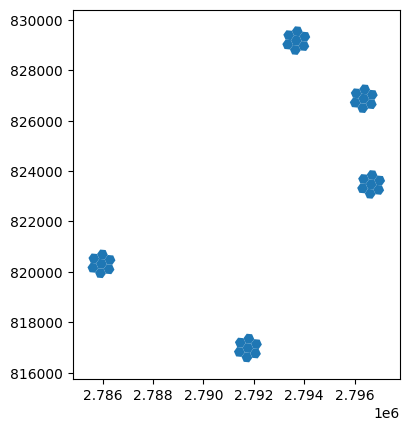

In [53]:
# plot
gdf_hexes_example[['neighborhood', 'geometry']].drop_duplicates().plot()

### Time Series

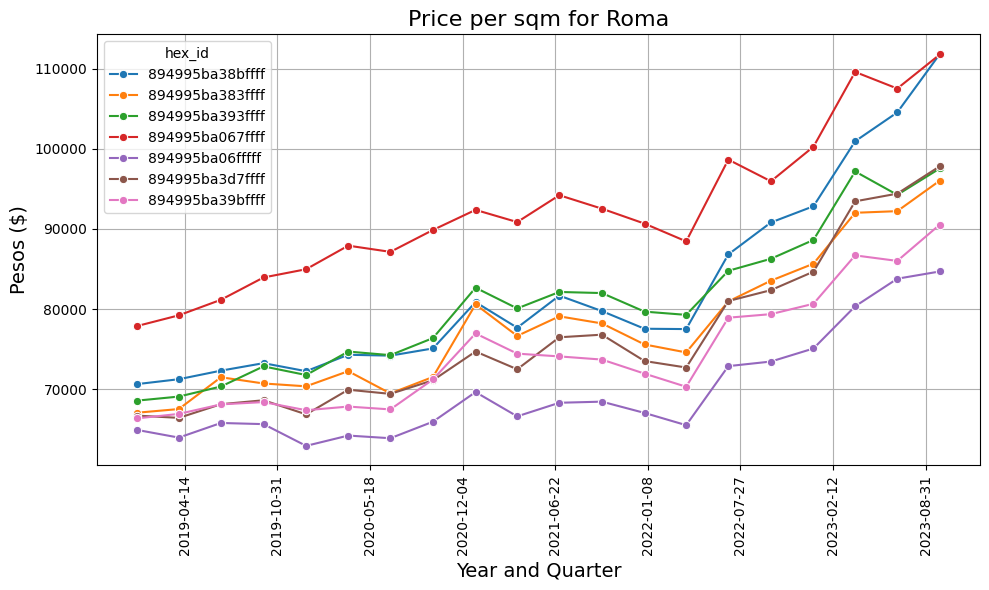

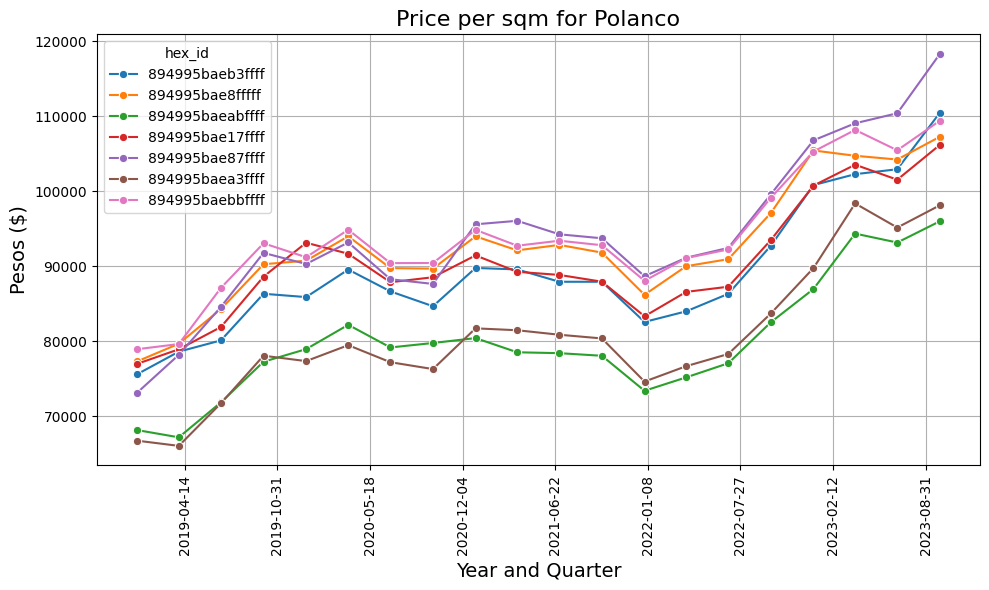

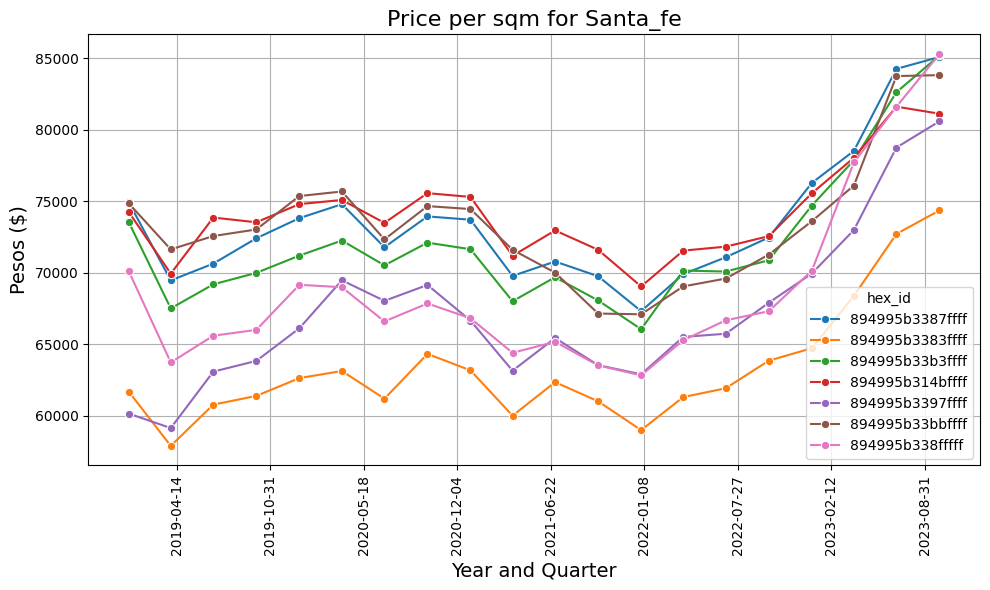

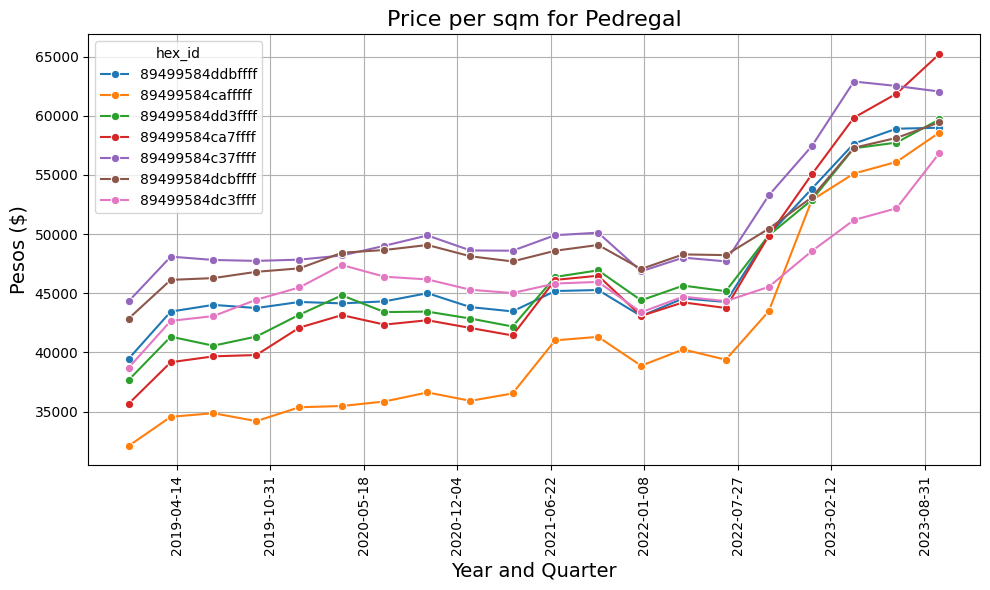

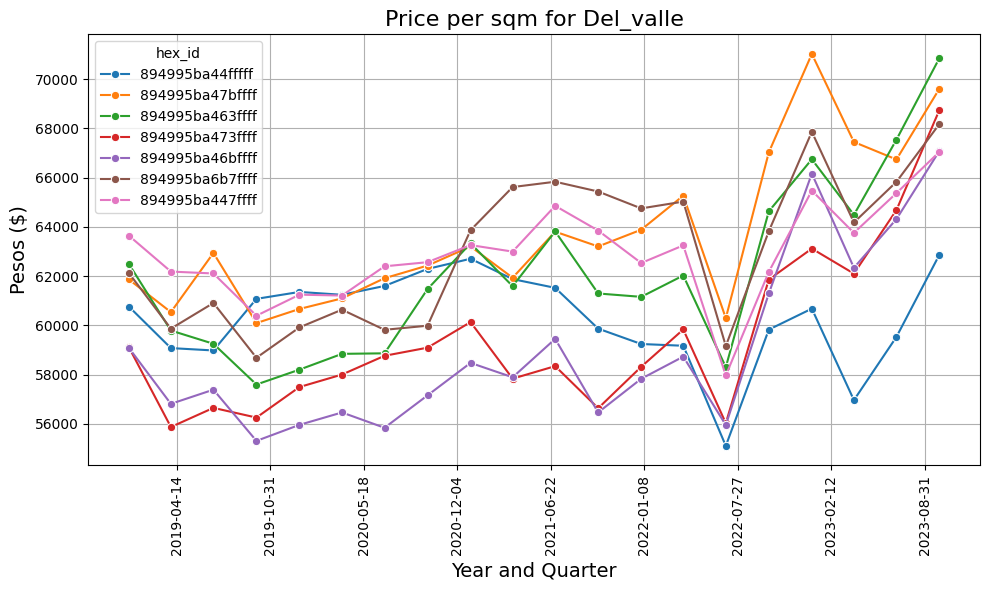

In [35]:
# for each neighborhood plot time series of housing index
for neighborhood in gdf_hexes_example['neighborhood'].unique():
    # subset
    gdf_plot = gdf_hexes_example.loc[lambda x:
        x['neighborhood'] == neighborhood
    ].copy()

    # plot
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.lineplot(
        data=gdf_plot,
        x='year_quarter',
        y=target_name_pred,
        hue='hex_id',
        marker='o',
        ax=ax
    )
    ax.set_title(f"Price per sqm for {neighborhood.capitalize()}", fontsize=16)
    ax.set_xlabel("Year and Quarter", fontsize=14)
    ax.set_ylabel("Pesos ($)", fontsize=14)

    # x ticks for each year
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=10))

    ax.grid(True)
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()


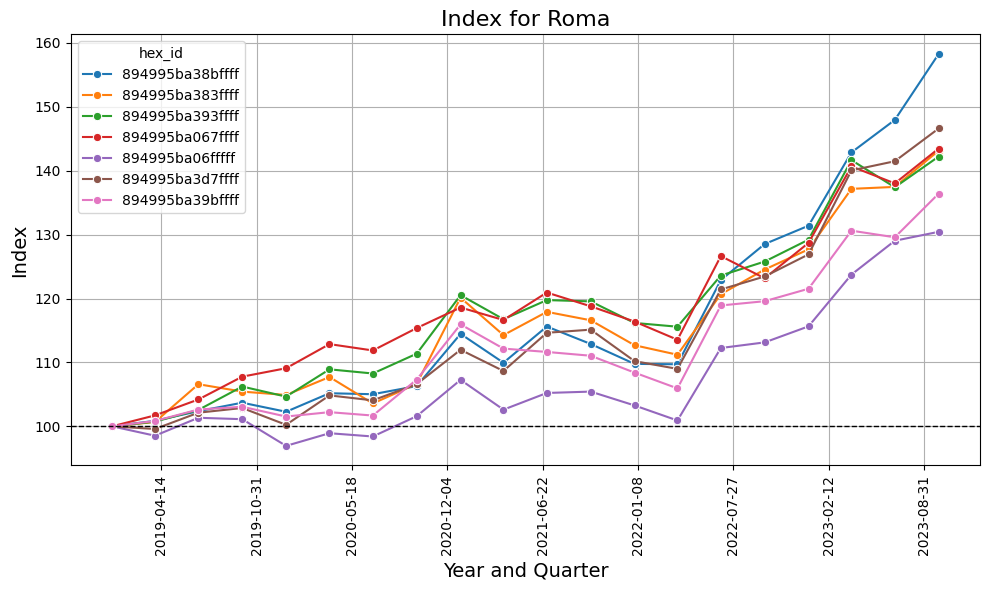

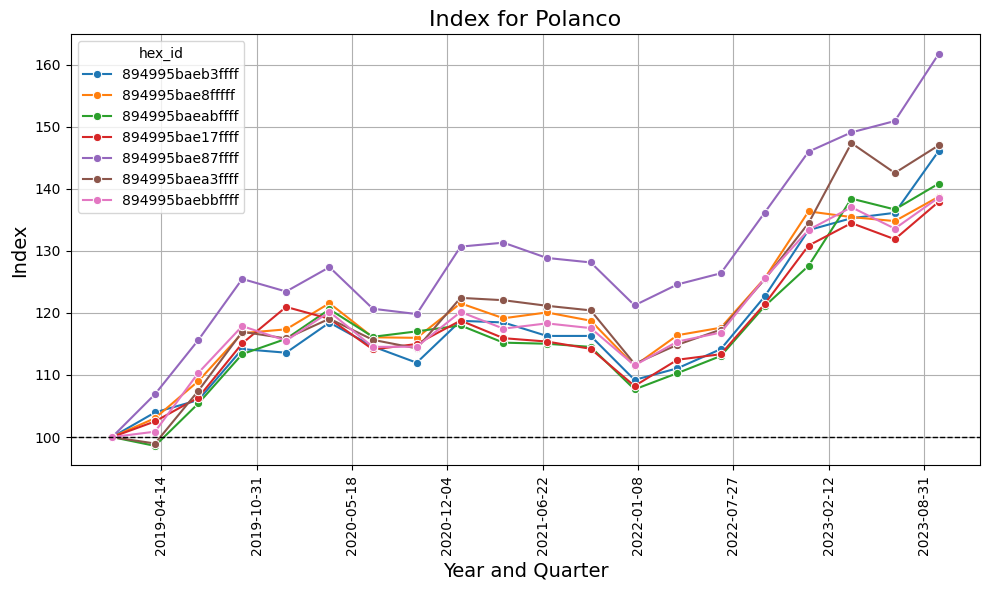

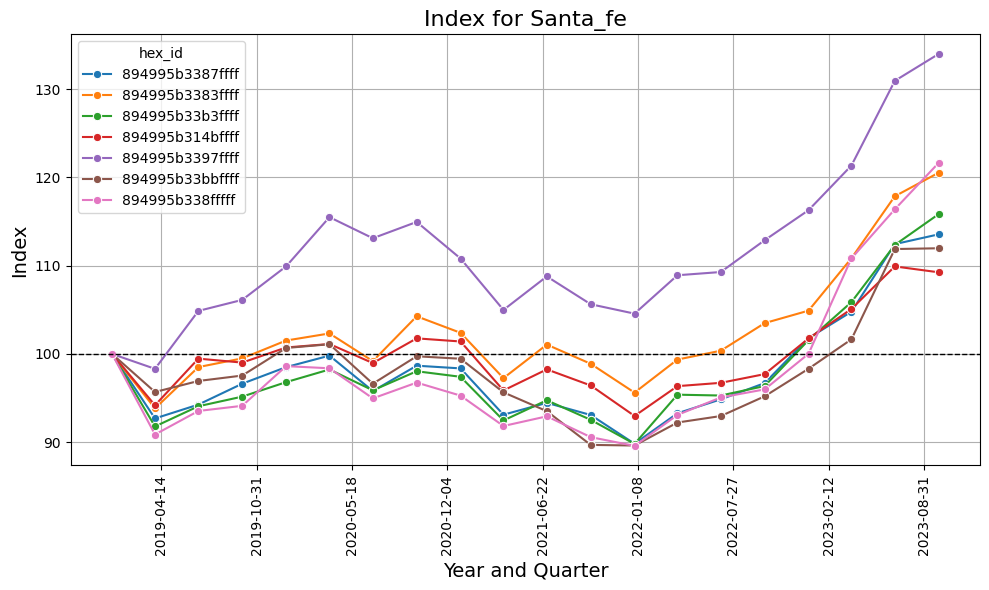

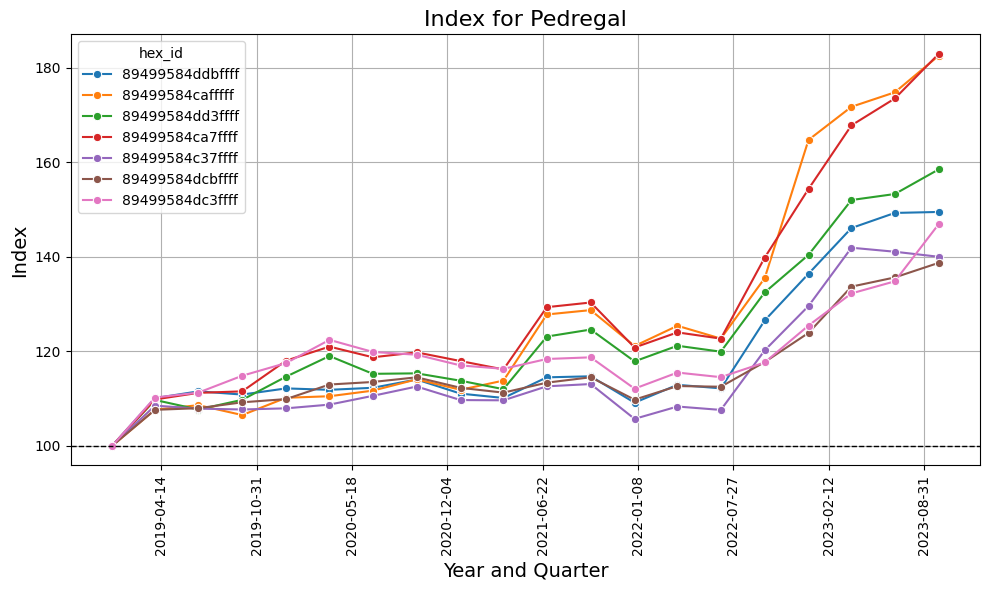

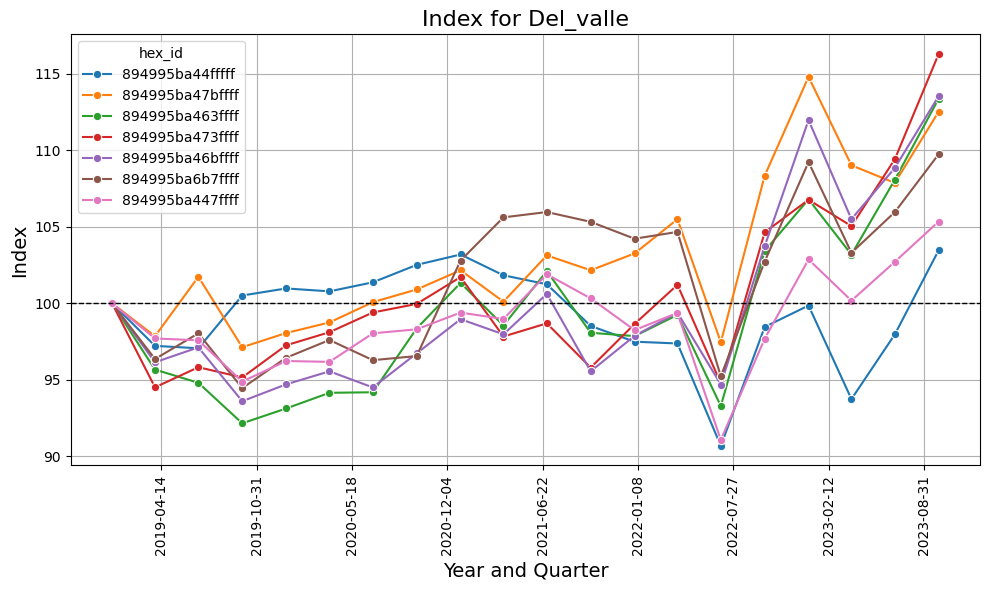

In [43]:
# for each neighborhood plot time series of housing index
for neighborhood in gdf_hexes_example['neighborhood'].unique():
    # subset
    gdf_plot = gdf_hexes_example.loc[lambda x:
        x['neighborhood'] == neighborhood
    ].copy()

    # plot
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.lineplot(
        data=gdf_plot,
        x='year_quarter',
        y='index',
        hue='hex_id',
        marker='o',
        ax=ax
    )
    ax.set_title(f"Index for {neighborhood.capitalize()}", fontsize=16)
    ax.set_xlabel("Year and Quarter", fontsize=14)
    ax.set_ylabel("Index", fontsize=14)

    # add horizontal line at y=100
    ax.axhline(100, color='k', linestyle='--', linewidth=1)

    # x ticks for each year
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=10))

    ax.grid(True)
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()


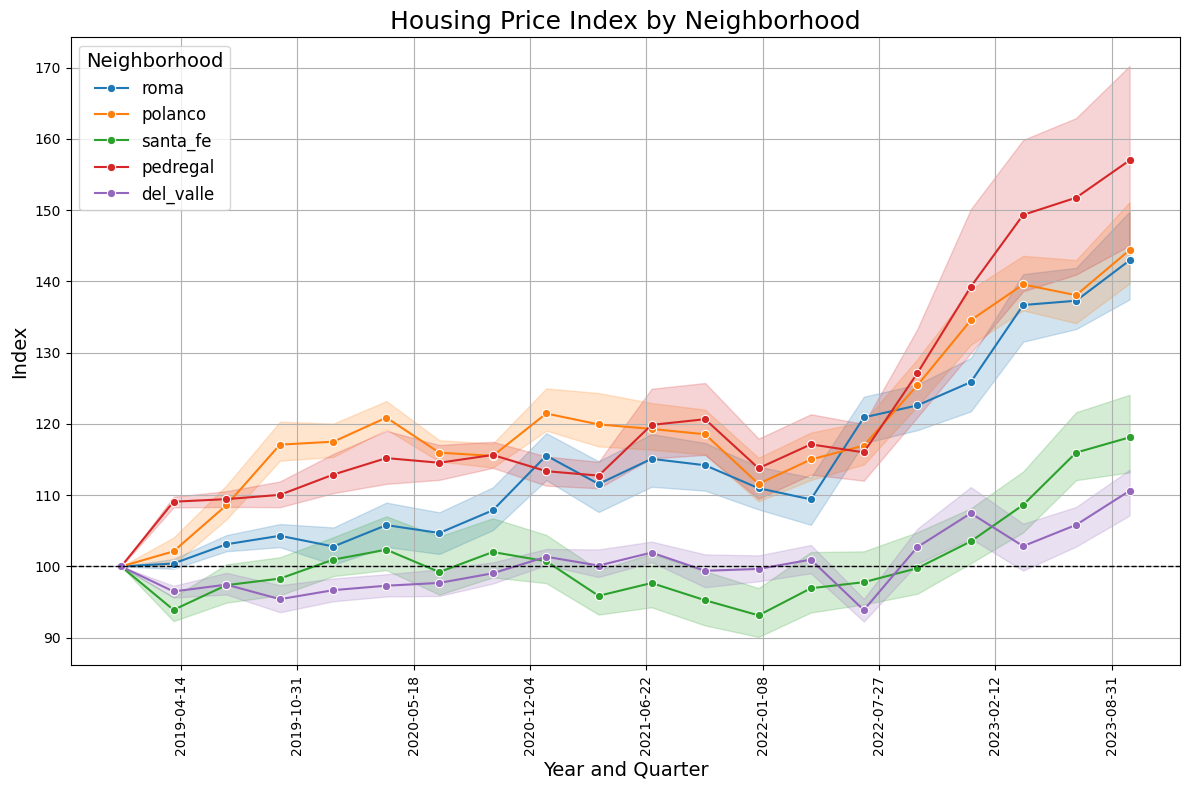

In [73]:
# plot all neighborhoods together
fig, ax = plt.subplots(figsize=(12, 8))
sns.lineplot(
    data=gdf_hexes_example,
    x='year_quarter',
    y='index',
    hue='neighborhood',
    marker='o',
    ax=ax,
    errorbar=('ci', 95)
)
ax.set_title("Housing Price Index by Neighborhood", fontsize=18)
ax.set_xlabel("Year and Quarter", fontsize=14)
ax.set_ylabel("Index", fontsize=14)

# add horizontal line at y=100
ax.axhline(100, color='k', linestyle='--', linewidth=1)

# x ticks for each year
ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=10))

ax.grid(True)
plt.xticks(rotation=90)
plt.legend(title='Neighborhood', fontsize=12, title_fontsize=14)
plt.tight_layout()
plt.show()



<Axes: >

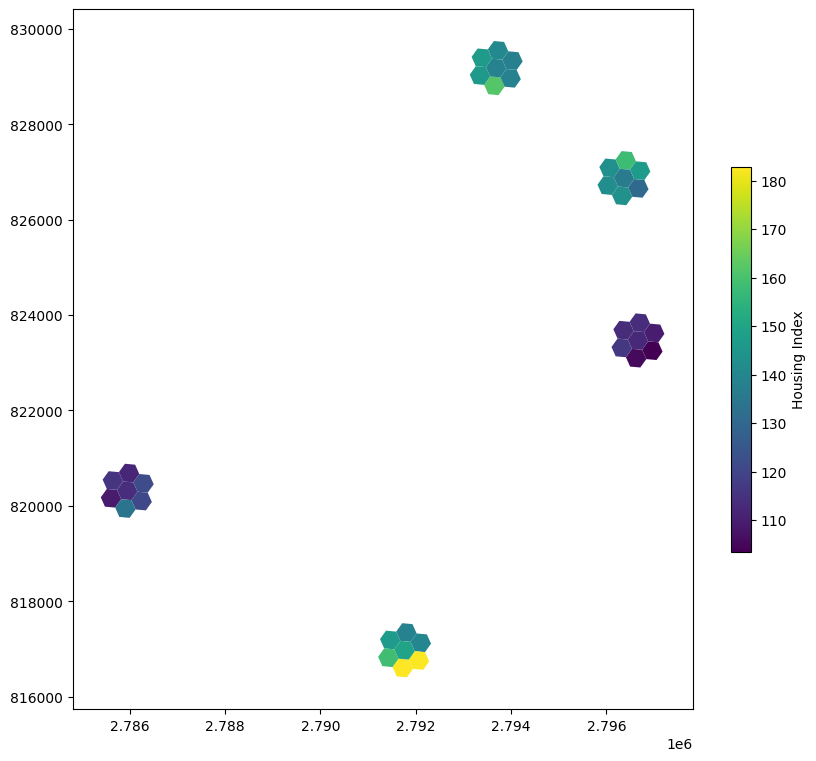

In [ ]:
# get last quarter per hex_id and plot map
gdf_last_quarter = (
    gdf_hexes_example
    .sort_values(['hex_id', 'year_quarter'])
    .groupby('hex_id')
    .tail(1)
    .copy()
    .reset_index(drop=True)
)

# plot change in the map
fig, ax = plt.subplots(figsize=(10, 10))
gdf_last_quarter.plot(
    column='index',
    cmap='viridis',
    legend=True,
    legend_kwds={'label': "Housing Index", 'shrink': 0.5},
    ax=ax
)

---
# Sandbox

In [54]:
gdf_hexes_example

,neighborhood,hex_id,geometry,ppsm_saleable_pred,year_quarter,base_price,index,index_pct_change
0,roma,894995ba38bffff,"POLYGON ((2796493.312 827048.050, 2796619.766 ...",70642.093750,2019-01-01,70642.093750,100.000000,NaN
1,roma,894995ba38bffff,"POLYGON ((2796493.312 827048.050, 2796619.766 ...",71251.164062,2019-04-01,70642.093750,100.862190,0.008622
2,roma,894995ba38bffff,"POLYGON ((2796493.312 827048.050, 2796619.766 ...",72319.460938,2019-07-01,70642.093750,102.374458,0.014993
3,roma,894995ba38bffff,"POLYGON ((2796493.312 827048.050, 2796619.766 ...",73254.257812,2019-10-01,70642.093750,103.697739,0.012926
4,roma,894995ba38bffff,"POLYGON ((2796493.312 827048.050, 2796619.766 ...",72251.140625,2020-01-01,70642.093750,102.277740,-0.013694
...,...,...,...,...,...,...,...,...
695,del_valle,894995ba447ffff,"POLYGON ((2796709.637 822901.278, 2796836.088 ...",62176.718750,2022-10-01,63648.285156,97.687973,0.072626
696,del_valle,894995ba447ffff,"POLYGON ((2796709.637 822901.278, 2796836.088 ...",65474.718750,2023-01-01,63648.285156,102.869568,0.053042
697,del_valle,894995ba447ffff,"POLYGON ((2796709.637 822901.278, 2796836.088 ...",63759.097656,2023-04-01,63648.285156,100.174103,-0.026203
698,del_valle,894995ba447ffff,"POLYGON ((2796709.637 822901.278, 2796836.088 ...",65374.515625,2023-07-01,63648.285156,102.712143,0.025336


In [ ]:
gdf_plot.head(2)

In [ ]:
f'{target_name}_pred'

In [ ]:
df_cross.info()

In [ ]:
gdf_plot.info()

In [ ]:
sns.lineplot(
    data=gdf_plot,
    x='year_quarter',
    y='ppsm_saleable_pred',
    # hue='hex_id',
    # marker='o',
    # ax=ax,
    # legend=False,
    # cmap='viridis'
)

In [ ]:
df_cross

In [ ]:
list(config_model['target'].keys())[0]

In [ ]:
df_properties.filter(like='quar')

In [ ]:
df_properties

In [ ]:
transformer.get_transformers()['target'].mean_

In [ ]:
gdf_hexes_example